# 第五部分：DeepAgent Skills 与渐进式披露 (Progressive Disclosure)
### *Alex 的顿悟：别再给 Agent 灌书，教它如何「翻书」*

在 Notebook 4 中，Alex 试图把所有业务规则塞进一个超级提示词（Mega-Prompt）。结果呢？Agent 就像被迫在 30 秒内读完一本百科全书——读到后面，忘了前面，出现幻觉、遗漏规则，成本还高得吓人。

Alex 终于意识到：**人类专家从来不会把整本手册背下来再工作**。财务部长脑中只有「财务知识目录」，遇到具体问题时才去翻对应的章节。

于是，Alex 采用了 DeepAgent 的 **Skills** 架构——一种让 AI 学会「翻书」而非「背书」的机制。

**核心原理：**
1. **元数据注入 (Metadata Injection)**：Agent 初始化时只加载技能的名字和描述。这就像给 Agent 一张**「技能目录」**。
2. **按需读取 (On-demand Reading)**：只有当 Agent 认为某个技能对当前任务有用时，它才会调用内置工具去读取 `SKILL.md` 的**「详细手册」**。

在这个笔记本中，我们将：
1. **见证技能目录的诞生**：看 `finance_pro` 和 `market_wizard` 两个 SKILL.md 如何成为 Agent 的「知识手册」。
2. **流式任务执行 (Streaming)**：开启流式模式，实时观察 Agent 是如何一步步查阅技能、分析数据、生成报表的。
3. **验证 Token 效率**：证明 Skills 模式相比 Mega-Prompt，在同等效果下节省了数十倍的 Token 消耗。

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain_core.tools import tool
from langchain_experimental.utilities import PythonREPL
from deepagents import create_deep_agent
from deepagents.backends.filesystem import FilesystemBackend
from deepagents.middleware.skills import SKILLS_SYSTEM_PROMPT

load_dotenv(override=True)

# 1. 准备技能目录
os.makedirs("skills/finance_pro", exist_ok=True)
os.makedirs("skills/market_wizard", exist_ok=True)

print("=== DeepAgent Skills Middleware 自动注入的提示词 ===\n")
print(SKILLS_SYSTEM_PROMPT)
print("=" * 60)


=== DeepAgent Skills Middleware 自动注入的提示词 ===

## Skills System

You have access to a skills library that provides specialized capabilities and domain knowledge.

{skills_locations}{skills_load_warnings}

Sources labeled "Deepagents" are specific to this agent tool; sources labeled "Agents" are shared across all agent tools on this machine.

**Available Skills:**

{skills_list}

**How to Use Skills (Progressive Disclosure):**

Skills follow a **progressive disclosure** pattern - you see their name and description above, but only read full instructions when needed:

1. **Recognize when a skill applies**: Check if the user's task matches a skill's description
2. **Read the skill's full instructions**: Use `read_file` on the path shown in the skill list above.
    Pass `limit=1000` since the default of 100 lines is too small for most skill files.
3. **Follow the skill's instructions**: SKILL.md contains step-by-step workflows, best practices, and examples
4. **Access supporting files**: Sk

## 2. 初始化流式 Agent
我们将开启流式模式，这样当 Agent 在进行长链条推理时，我们能实时看到输出。


In [2]:
model = init_chat_model(
    model="agnes-2.0-flash",
    model_provider="openai",
    base_url=os.getenv("AGNES_BASE_URL"),
    api_key=os.getenv("AGNES_API_KEY"),
    streaming=True
)

root_dir = Path.cwd()
backend = FilesystemBackend(root_dir=str(root_dir))

repl = PythonREPL()

@tool
def python_analyst(code: str):
    """Execute Python analysis. Has access to enterprise_data/ files."""
    return repl.run(code)

@tool
def generate_report(csv_path: str):
    """
    Generate a professional GlobalCorp visual report (bar + pie charts) for any CSV.
    The CSV should have columns for: region, quantity, unit price, product category, and discount.
    Handles both standard (Region, Quantity, Discount) and cleaned naming conventions.
    """
    import matplotlib.pyplot as plt
    import seaborn as sns
    import pandas as pd
    plt.rcParams["font.sans-serif"] = ["PingFang SC", "Arial Unicode MS"]
    plt.rcParams["axes.unicode_minus"] = False

    df = pd.read_csv(csv_path)
    col_map = {c: c.lower().strip() for c in df.columns}
    reverse_map = {v: k for k, v in col_map.items()}

    region_col = reverse_map.get("region")
    qty_col = reverse_map.get("quantity") or reverse_map.get("qty")
    price_col = reverse_map.get("unit_price") or reverse_map.get("price_per_unit") or reverse_map.get("unit price")
    cat_col = reverse_map.get("product_category") or reverse_map.get("prod_cat") or reverse_map.get("product category")
    discount_col = reverse_map.get("discount") or reverse_map.get("rebate")

    if not all([region_col, qty_col, price_col, cat_col]):
        return f"错误：CSV 缺少必要列。找到的列: {list(df.columns)}"

    df[price_col] = df[price_col].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False).astype(float)

    if discount_col:
        df["Total_Revenue"] = (df[qty_col].astype(float) * df[price_col]) - df[discount_col].astype(float)
    else:
        df["Total_Revenue"] = df[qty_col].astype(float) * df[price_col]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    region_data = df.groupby(region_col)["Total_Revenue"].sum().sort_values(ascending=False)
    sns.barplot(x=region_data.index, y=region_data.values, hue=region_data.index, ax=ax1, palette="viridis", legend=False)
    ax1.set_title("按地区汇总的净收入", fontsize=14, fontweight="bold")
    ax1.set_ylabel("收入 (USD)")

    cat_data = df.groupby(cat_col)["Total_Revenue"].sum()
    ax2.pie(cat_data, labels=cat_data.index, autopct="%1.1f%%", startangle=140,
            colors=sns.color_palette("pastel"), wedgeprops={"edgecolor": "white", "linewidth": 2})
    centre_circle = plt.Circle((0, 0), 0.70, fc="white")
    ax2.add_artist(centre_circle)
    ax2.set_title("产品类别贡献率", fontsize=14, fontweight="bold")

    plt.suptitle(f"GlobalCorp 业务分析报告: {csv_path}", fontsize=18)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()
    return "报告生成成功。"

# 注意：不传 system_prompt，让 middleware 自动注入技能提示
agent = create_deep_agent(
    model=model,
    tools=[python_analyst, generate_report],
    backend=backend,
    skills=[str(root_dir / "skills")],
)


/var/folders/gw/b1s29s7934s_dbr99tf9x4fm0000gp/T/ipykernel_76645/3387149002.py:10: LangChainDeprecationWarning: `FilesystemBackend` `virtual_mode` default will change in deepagents==0.6.0; please specify `virtual_mode` explicitly. Note: `virtual_mode` is for virtual path semantics (e.g., `CompositeBackend` routing) and optional path-based guardrails; it does not provide sandboxing or process isolation. Security note: leaving `virtual_mode=False` allows absolute paths and `'..'` to bypass `root_dir`. Consult the API reference for details.
  backend = FilesystemBackend(root_dir=str(root_dir))


## 4. 执行并观察：渐进式披露的实况转播
请注意观察：
1. **第一步**：你会看到 LLM 的输入中包含了技能的 `name` 和 `description`，但没有具体规则。
2. **第二步**：你会看到 Agent 发现需要财务规则，调用了 `read_skill`。
3. **第三步**：再次发送给 LLM 的输入中，`finance_pro` 的全文被加载了进来。

Skill 'finance_pro' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/finance_pro/SKILL.md does not follow Agent Skills specification: name must be lowercase alphanumeric with single hyphens only. Consider renaming for spec compliance.
Skill 'inventory_management' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/inventory_management/SKILL.md does not follow Agent Skills specification: name must be lowercase alphanumeric with single hyphens only. Consider renaming for spec compliance.
Skill 'market_wizard' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/market_wizard/SKILL.md does not follow Agent Skills specification: name must be lowercase alphanumeric with single hyphens only. Consider renaming for spec compliance.
Skill 'sales_analytics' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/sales_analytics/SKILL.md does not follow Agent Skill

Graph: root
Node: SkillsMiddleware.before_agent
Graph: root
Node: PatchToolCallsMiddleware.before_agent
Graph: root
Node: model


╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│ 🔧 Tool Call: read_file                                                                                         │
│    Args: {                                                                                                      │
│   "file_path":                                                                                                  │
│ "/Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/data/modern_marketing.csv",        │
│   "limit": 100                                                                                                  │
│ }                                                                                                               │
│    ID: call_4e76792716434e28a22c2437                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: TodoListMiddleware.after_model
Graph: root
Node: tools


╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Error: File                                                                                                     │
│ '/Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/data/modern_marketing.csv' not     │
│ found                                                                                                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

...

Graph: root
Node: TodoListMiddleware.after_model
Graph: root
Node: tools


╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Updated todo list to [{'content': '读取并清洗 modern_marketing.csv 数据（market_wizard 技能）', 'status':       │
│ 'completed'}, {'content': '应用财务规则（finance_pro 技能）计算净收入和税额', 'status': 'completed'},           │
│ {'content': '生成完整分析报告（含可视化图表）', 'status': 'in_progress'}]                                       │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: model


╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│ 现在生成可视化报告：                                                                                            │
│                                                                                                                 │
│                                                                                                                 │
│                                                                                                                 │
│ 🔧 Tool Call: generate_report                                                                                   │
│    Args: {                                                                                                      │
│   "csv_path":                                                                                                   │
│ "/Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/enterprise_data/cleaned_marketing. │
│ csv"                                                                                                            │
│ }                                                                                                               │
│    ID: call_60a685a3d19d49cc86cd077a                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: TodoListMiddleware.after_model


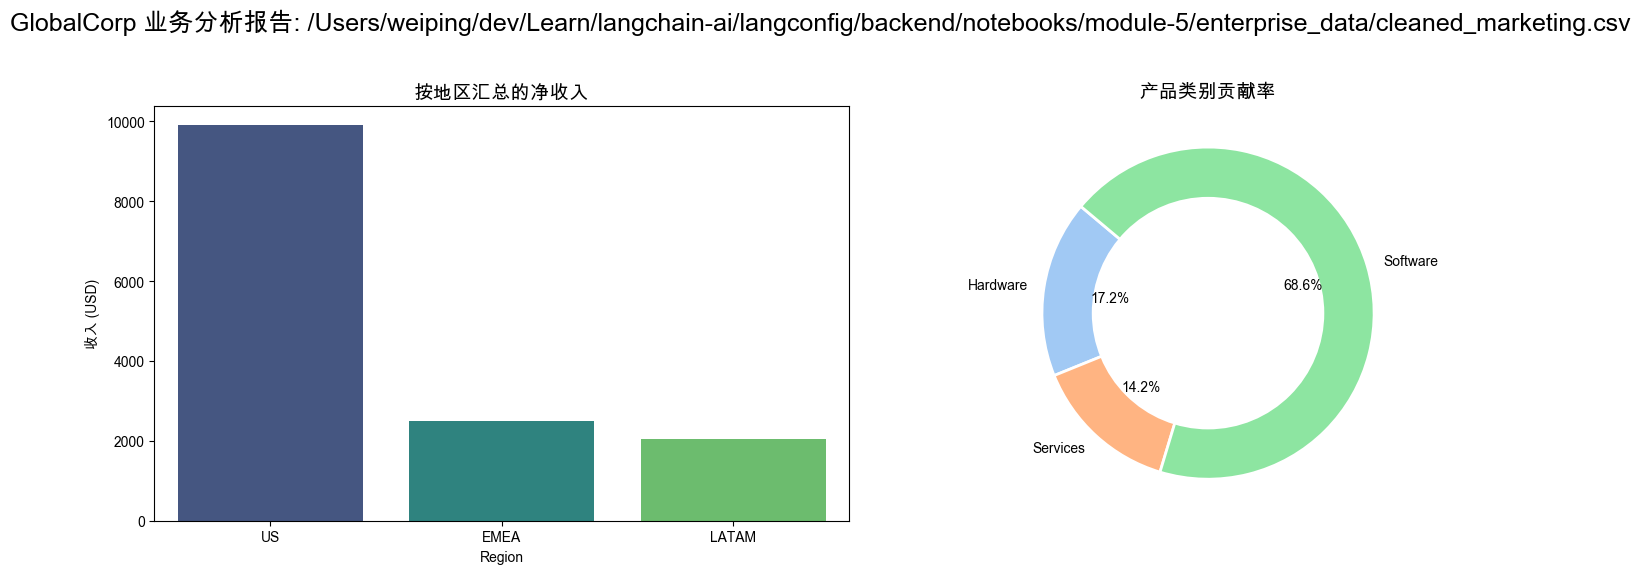

Graph: root
Node: tools


╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ 报告生成成功。                                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: model


╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│ 🔧 Tool Call: write_todos                                                                                       │
│    Args: {                                                                                                      │
│   "todos": [                                                                                                    │
│     {                                                                                                           │
│       "content": "读取并清洗 modern_marketing.csv 数据（market_wizard 技能）",                                  │
│       "status": "completed"                                                                                     │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "应用财务规则（finance_pro 技能）计算净收入和税额",                                            │
│       "status": "completed"                                                                                     │
│     },                                                                                                          │
│     {                                                                                                           │
│       "content": "生成完整分析报告（含可视化图表）",                                                            │
│       "status": "completed"                                                                                     │
│     }                                                                                                           │
│   ]                                                                                                             │
│ }                                                                                                               │
│    ID: call_25b5fdb2504e44909f5345a3                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: TodoListMiddleware.after_model
Graph: root
Node: tools


╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Updated todo list to [{'content': '读取并清洗 modern_marketing.csv 数据（market_wizard 技能）', 'status':       │
│ 'completed'}, {'content': '应用财务规则（finance_pro 技能）计算净收入和税额', 'status': 'completed'},           │
│ {'content': '生成完整分析报告（含可视化图表）', 'status': 'completed'}]                                         │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: model


╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│ ---                                                                                                             │
│                                                                                                                 │
│ # 📊 Modern Marketing 数据分析报告                                                                              │
│                                                                                                                 │
│ ## 一、数据概览                                                                                                 │
│                                                                                                                 │
│ | 指标 | 数值 |                                                                                                 │
│ |------|------|                                                                                                 │
│ | 总交易数 | 3 |                                                                                                │
│ | 覆盖地区 | US, EMEA, LATAM |                                                                                  │
│ | 产品类别 | Software, Hardware, Services |                                                                     │
│                                                                                                                 │
│ ## 二、数据清洗过程（market_wizard 技能）                                                                       │
│                                                                                                                 │
│ 1. **列名映射**：将市场数据列名映射为标准列名                                                                   │
│    - `market` → `Region`                                                                                        │
│    - `qty` → `Quantity`                                                                                         │
│    - `prod_cat` → `Product_Category`                                                                            │
│    - `price_per_unit` → `Unit_Price`                                                                            │
│    - `rebate` → `Discount`                                                                                      │
│                                                                                                                 │
│ 2. **数据清洗**：                                                                                               │
│    - 移除 `Unit_Price` 中的 `$` 符号和千位分隔符 `,`，转换为浮点数                                              │
│    - 确保 `Quantity` 为整数类型                                                                                 │
│    - 确保 `Discount` 为浮点类型                                                                                 │
│                                                                                                                 │
│ 3. **清洗后数据已保存至**：`enterprise_data/cleaned_marketing.csv`                                              │
│                                                                                                                 │
│ ## 三、详细交易数据                                                                                             │
│                                                                                                                 │
│ | 交易ID | 地区 | 产品类别 | 数量 | 单价 | 折扣 | 总收入 | 净收入 | 税率 | 税额 | 税后净收入 |                  │
│ |--------|------|----------|------|------|------|--------|--------|------|------|------------|                  │
│ | MKT_999 | US | Software | 20 | $500.00 | $100.00 | $10,000.00 | $9,900.00 | 8% | $792.00 | $9,108.00 |        │
│ | MKT_1000 | EMEA | Hardware | 2 | $1,250.00 | $10.00 | $2,500.00 | $2,490.00 | 15% | $373.50 | $2,116.50 |     │
│ | MKT_1001 | LATAM | Services | 1 | $2,100.00 | $50.00 | $2,100.00 | $2,050.00 | 0% 

Graph: root
Node: TodoListMiddleware.after_model


{'messages': [HumanMessage(content='请分析 modern_marketing.csv 并给我一份完整的分析报告', additional_kwargs={}, response_metadata={}, id='92914364-18b0-4d03-ab9c-dee009a2f7e3'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'agnes-2.0-flash', 'model_provider': 'openai'}, id='lc_run--019efa5e-940a-7b32-ad3d-2abf43f5adcf', tool_calls=[{'name': 'read_file', 'args': {'file_path': '/Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/data/modern_marketing.csv', 'limit': 100}, 'id': 'call_4e76792716434e28a22c2437', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 7727, 'output_tokens': 50, 'total_tokens': 7770, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}),
  ToolMessage(content="Error: File '/Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/data/modern_marketing.csv' not found", name='read_file', id='04

In [3]:
from utils import stream_agent
import asyncio

query = "请分析 modern_marketing.csv 并给我一份完整的分析报告"

await stream_agent(
    agent,
    {"messages": [{"role": "user", "content": query}]},
    config={"recursion_limit": 50},
)


## 5. 结论：为什么 Alex 终于成功了？

观察追踪日志，你会发现 Skills 模式的三个核心优势：

1. **Token 效率**：初始请求非常短（只有目录）。比起 Notebook 4 的全量注入，我们节省了大量的“背景 Token”。
2. **零干扰**：如果用户问的是天气，Agent 根本不会去读财务手册，从而避免了不相关规则带来的幻觉。
3. **解耦与动态性**：如果你现在去修改 `skills/finance_pro/SKILL.md`，Agent 在下一次调用 `read_skill` 时会立刻获得新知识，而无需重启或重新训练模型。

### Alex 的最终寄语：
“不要试图让 Agent 成为一个全知全能的神。要让它成为一个善于学习、懂得按需获取知识的**专业工作者**。这就是 DeepAgent Skills 的真谛。”